# Laboratorio #4 – Análisis exploratorio de datos (EDA)

**Universidad Técnica Nacional**  
**Minería de datos – ISW-911**  
**Asignación grupal (investigación)**

**Integrantes:**
- Karol Miranda Mora
- Katherine Solis Ramirez
- Dylan Jimenez Alfaro
- Josué Alvarez Villalobos

---

**Conjunto de datos:** Duración de expedientes terminados del Observatorio Judicial de Costa Rica (2026).  
**Fuente:** Portal de Datos Abiertos del Poder Judicial de Costa Rica  
https://datosabiertospj.poder-judicial.go.cr/dataset/duracion-de-expedientes-terminados-del-observatorio-judicial-de-costa-rica

**Cómo está organizado el trabajo:**

| Sección | Responsable |
|---|---|
| 1. Exploración inicial | Karol |
| 2. Limpieza de datos | Katherine |
| 3. Transformación | Dylan |
| 4. Análisis y resultados | Josué |


## 1. Exploración inicial (Karol)

### 1.1 Librerías

In [1]:
%pip install pandas numpy matplotlib seaborn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

### 1.2 Lectura del conjunto de datos desde Git

El archivo se subió al repositorio de GitHub (público) en formato `.csv.gz`, que es un CSV comprimido. El archivo original en Excel pesa 31 MB y el CSV sin comprimir unos 91 MB, así que se prefirió comprimirlo (queda en unos 6 MB) para que el notebook cargue rápido.

Pandas lee el `.csv.gz` directamente desde la URL. Las columnas de códigos se leen como texto para no perder los ceros a la izquierda (por ejemplo `0215`).

In [2]:
URL = "https://raw.githubusercontent.com/Kyaroruki/Laboratorio-4-Mineria-Datos/main/datos/duracion_terminados.csv.gz"
RUTA_LOCAL = "datos/duracion_terminados.csv.gz"   # respaldo si no hay internet

# Los códigos se leen como texto para conservar los ceros a la izquierda
tipos = {"CodClaseAsu": "str", "CodProcedimiento": "str", "CodFase": "str"}

try:
    df = pd.read_csv(URL, compression="gzip", dtype=tipos)
    print("Datos leídos desde GitHub")
except Exception as e:
    print(f"No se pudo leer desde GitHub ({type(e).__name__}). Se usa el archivo local.")
    df = pd.read_csv(RUTA_LOCAL, compression="gzip", dtype=tipos)

print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}")

Datos leídos desde GitHub
Filas: 309,635 | Columnas: 23


### 1.3 Funciones básicas para ver las características del conjunto de datos

In [3]:
# Primeras filas
df.head()

,CodCircuito,DescCircuito,DescMateria,DescTipoDespacho,CodDespacho,DescDespacho,Año,Numero_Mes,CodClaseAsu,DescClaseAsu,CodProcedimiento,Procedimiento,DescEstadoAsunto,AgrEstadoAsunto,CodFase,Fase,TermiMedAlterna,TermiConciliacion,Cant,DurDias,Completitud,Desc_Delito,Ref_Civil
0,11,II CIRCUITO JUDICIAL DE LIMÓN (POCOCÍ),PENAL,FISCALÍA,485,FISCALÍA ADJUNTA DEL II CIRCUITO JUDICIAL DE L...,2026,3,0215,DENUNCIA EN DESPACHO,NaN,ORDINARIO,ACUS. FISCAL (SIN ACIV. RESAR.),Acusación,NaN,Etapa Preparatoria,No,NaN,1,615.00,COMPLETA,INCUMPLIMIENTO O ABUSO PATRIA POTESTAD,NaN
1,11,II CIRCUITO JUDICIAL DE LIMÓN (POCOCÍ),PENAL,FISCALÍA,485,FISCALÍA ADJUNTA DEL II CIRCUITO JUDICIAL DE L...,2026,3,0215,DENUNCIA EN DESPACHO,NaN,ORDINARIO,INCOMPETENCIA (JURISDICCIONAL),NaN,NaN,Etapa Preparatoria,No,NaN,1,0.00,COMPLETA,INTRODUCCIÓN DE DROGA DEL CENTRO PENITENCIARIO,NaN
2,11,II CIRCUITO JUDICIAL DE LIMÓN (POCOCÍ),PENAL,FISCALÍA,485,FISCALÍA ADJUNTA DEL II CIRCUITO JUDICIAL DE L...,2026,3,0215,DENUNCIA EN DESPACHO,NaN,ORDINARIO,INCOMPETENCIA (JURISDICCIONAL),NaN,NaN,Etapa Preparatoria,No,NaN,1,"1,409.00",COMPLETA,PREVARICATO,NaN
3,11,II CIRCUITO JUDICIAL DE LIMÓN (POCOCÍ),PENAL,FISCALÍA,485,FISCALÍA ADJUNTA DEL II CIRCUITO JUDICIAL DE L...,2026,3,0215,DENUNCIA EN DESPACHO,NaN,ORDINARIO,REMITIDO OTRO DESPACHO DEL MINISTERIO PÚBLICO ...,NaN,NaN,Etapa Preparatoria,No,NaN,1,10.00,COMPLETA,AGRESIÓN CON ARMAS,NaN
4,11,II CIRCUITO JUDICIAL DE LIMÓN (POCOCÍ),PENAL,FISCALÍA,485,FISCALÍA ADJUNTA DEL II CIRCUITO JUDICIAL DE L...,2026,3,0215,DENUNCIA EN DESPACHO,NaN,ORDINARIO,"SOL. DESESTIMACIÓN, ART. 299 (ELEMENTOS PROBAT...",NaN,NaN,Etapa Intermedia,No,NaN,1,16.00,COMPLETA,AMENAZA A UN FUNCIONARIO PÚBLICO,NaN


In [4]:
# Últimas filas
df.tail()

,CodCircuito,DescCircuito,DescMateria,DescTipoDespacho,CodDespacho,DescDespacho,Año,Numero_Mes,CodClaseAsu,DescClaseAsu,CodProcedimiento,Procedimiento,DescEstadoAsunto,AgrEstadoAsunto,CodFase,Fase,TermiMedAlterna,TermiConciliacion,Cant,DurDias,Completitud,Desc_Delito,Ref_Civil
309630,9,I Circuito Judicial de Alajuela,VIOLENCIA DOMÉSTICA,Juzgado,1473,JUZGADO CONTRAVENCIONAL DE OROTINA (VIOLENCIA ...,2026,9,1111,VIOLENCIA DOMÉSTICA,NaN,VIOLENCIA DOMÉSTICA ORDINARIO ESCRITO,RECHAZO DE PLANO,NaN,NaN,NaN,NaN,No,2,71.00,COMPLETA,V.D. AMENAZAS AGRAVADAS,NaN
309631,9,I Circuito Judicial de Alajuela,VIOLENCIA DOMÉSTICA,Juzgado,1477,JUZGADO CONTRAVENCIONAL DE POÁS (VIOLENCIA DOM...,2026,5,1111,VIOLENCIA DOMÉSTICA,NaN,VIOLENCIA DOMÉSTICA (ORDINARIO),LEVANTA MEDIDA (POR VENCIMIENTO DEL PLAZO),NaN,NaN,NaN,NaN,No,107,"47,679.00",INCOMPLETA,IGNORADO,NaN
309632,9,I Circuito Judicial de Alajuela,VIOLENCIA DOMÉSTICA,Juzgado,1477,JUZGADO CONTRAVENCIONAL DE POÁS (VIOLENCIA DOM...,2026,5,3186,PROCESO DE PROTECCIÓN PARA PERSONA ADULTA MAYOR,NaN,SIN PARENTESCO,LEVANTA MEDIDA (POR VENCIMIENTO DEL PLAZO),NaN,NaN,NaN,NaN,No,2,876.00,INCOMPLETA,IGNORADO,NaN
309633,9,I Circuito Judicial de Alajuela,VIOLENCIA DOMÉSTICA,Juzgado,1477,JUZGADO CONTRAVENCIONAL DE POÁS (VIOLENCIA DOM...,2026,7,1091,TESTIMONIO DE PIEZAS,NaN,VD PARA MP POR INCUMPLIMIENTO MEDIDA DESOBEDIE...,TESTIMONIOS DE PIEZAS REMITIDOS A OTRAS OFICINAS,NaN,NaN,NaN,NaN,No,1,11.00,COMPLETA,DESCONOCIDO,NaN
309634,9,I Circuito Judicial de Alajuela,VIOLENCIA DOMÉSTICA,Juzgado,1477,JUZGADO CONTRAVENCIONAL DE POÁS (VIOLENCIA DOM...,2026,9,1111,VIOLENCIA DOMÉSTICA,NaN,VIOLENCIA DOMÉSTICA (ORDINARIO) MUJERES VÍCTIM...,LEVANTA MEDIDA (POR VENCIMIENTO DEL PLAZO),NaN,NaN,NaN,NaN,No,1,428.00,COMPLETA,IGNORADO,NaN


In [5]:
# Cantidad de filas y columnas
print("Forma del dataset (filas, columnas):", df.shape)

Forma del dataset (filas, columnas): (309635, 23)


In [6]:
# Tipos de dato, cantidad de valores no nulos y memoria usada
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 309635 entries, 0 to 309634
Data columns (total 23 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   CodCircuito        309635 non-null  int64  
 1   DescCircuito       309635 non-null  object 
 2   DescMateria        309635 non-null  object 
 3   DescTipoDespacho   309635 non-null  object 
 4   CodDespacho        309635 non-null  int64  
 5   DescDespacho       309635 non-null  object 
 6   Año                309635 non-null  int64  
 7   Numero_Mes         309635 non-null  int64  
 8   CodClaseAsu        309581 non-null  object 
 9   DescClaseAsu       309038 non-null  object 
 10  CodProcedimiento   0 non-null       object 
 11  Procedimiento      309635 non-null  object 
 12  DescEstadoAsunto   309635 non-null  object 
 13  AgrEstadoAsunto    85216 non-null   object 
 14  CodFase            0 non-null       object 
 15  Fase               276887 non-null  object 
 16  Te

In [7]:
# Estadísticas de las columnas numéricas
df.describe()

,CodCircuito,CodDespacho,Año,Numero_Mes,Cant,DurDias
count,"309,635.00","309,635.00","309,635.00","309,635.00","309,635.00","309,362.00"
mean,16.28,882.22,"2,026.00",5.06,2.86,"1,357.84"
std,17.94,546.19,0.00,2.56,15.45,"21,223.85"
min,1.00,4.00,"2,026.00",1.00,1.00,0.00
25%,4.00,472.00,"2,026.00",3.00,1.00,22.00
50%,10.00,687.00,"2,026.00",5.00,1.00,98.00
75%,18.00,"1,260.00","2,026.00",7.00,2.00,414.00
max,72.00,"2,106.00","2,026.00",9.00,"1,871.00","3,155,804.00"


In [8]:
# Resumen de las columnas de texto
df.describe(include=["object", "string"]).T

,count,unique,top,freq
DescCircuito,309635,79,I CIRCUITO JUDICIAL DE SAN JOSÉ,35065
DescMateria,309635,23,PENAL,170009
DescTipoDespacho,309635,71,FISCALÍA,84919
DescDespacho,309635,907,FISCALÍA ADJUNTA DEL I CIRCUITO JUDICIAL DE AL...,3395
CodClaseAsu,309581,726,0215,32538
DescClaseAsu,309038,617,DENUNCIA EN DESPACHO,36142
CodProcedimiento,0,0,NaN,NaN
Procedimiento,309635,569,ORDINARIO,154319
DescEstadoAsunto,309635,642,"SOL. DESESTIMACIÓN, ART. 299 (ELEMENTOS PROBAT...",18391
AgrEstadoAsunto,85216,45,Acusación,17430


In [9]:
# Cantidad de valores distintos por columna
df.nunique().sort_values(ascending=False)

,0
DurDias,11515
CodDespacho,926
DescDespacho,907
CodClaseAsu,726
DescEstadoAsunto,642
Desc_Delito,635
DescClaseAsu,617
Procedimiento,569
Cant,344
Fase,131


In [10]:
# Una muestra al azar
df.sample(5, random_state=42)

,CodCircuito,DescCircuito,DescMateria,DescTipoDespacho,CodDespacho,DescDespacho,Año,Numero_Mes,CodClaseAsu,DescClaseAsu,CodProcedimiento,Procedimiento,DescEstadoAsunto,AgrEstadoAsunto,CodFase,Fase,TermiMedAlterna,TermiConciliacion,Cant,DurDias,Completitud,Desc_Delito,Ref_Civil
184325,5,CIRCUITO JUDICIAL DE HEREDIA,LABORAL,TRIBUNAL DE TRABAJO,809,TRIBUNAL DE APELACIÓN CIVIL Y TRABAJO DE HERED...,2026,5,JT001,ORDINARIO DE DESPIDO-PRIVADO,NaN,DE CESANTÍA U OTROS EXTREMOS,SENTENCIA,NaN,NaN,4. EN EJECUCION,NaN,No,1,115.00,COMPLETA,NO DELITOS,NaN
178220,47,I CIRCUITO JUDICIAL DE LIMÓN (BATÁN-MATINA),PENAL,FISCALÍA,1521,FISCALÍA DE BATÁN (PENAL),2026,3,0216,DENUNCIA POR ESCRITO,NaN,ORDINARIO,"SOL. DESESTIMACIÓN, ART. 299 (ELEMENTOS PROBAT...",NaN,NaN,Etapa Intermedia,No,NaN,1,169.00,COMPLETA,DIFUSIÓN DE PORNOGRAFÍA,NaN
294564,5,CIRCUITO JUDICIAL DE HEREDIA,PENAL JUVENIL,FISCALÍA PENAL JUVENIL,811,FISCALÍA ADJUNTA DE HEREDIA (PENAL JUVENIL),2026,2,0215,DENUNCIA EN DESPACHO,NaN,ESPECIAL,SOB.DEF. PRESCRIP.ART.31 C.P.P.,Sobreseimiento definitivo,NaN,Fase Conclusiva de la Investigación,No,NaN,1,242.00,COMPLETA,DESÓRDENES,NaN
162213,42,CIRCUITO JUDICIAL DE PUNTARENAS (GARABITO),TRÁNSITO,JUZGADO DE TRÁNSITO,1598,JUZGADO CONTRAVENCIONAL DE GARABITO (TRÁNSITO),2026,4,0540,COLISIÓN ENTRE VEHÍCULOS-ACCIDENTE SIMPLE,NaN,COLISIÓN,INCOMPETENCIA,Incompentencia,NaN,1. Inicial,NaN,No,7,211.00,COMPLETA,DESCONOCIDO,NaN
79087,11,Circuito Judicial de Heredia,VIOLENCIA DOMÉSTICA,Juzgado,1612,"JUZGADO DE PENSIONES, CONTRA LA VIOLENCIA DOMÉ...",2026,8,1111,VIOLENCIA DOMÉSTICA,NaN,VIOLENCIA DOMÉSTICA ORDINARIO VERBAL (MUJERES ...,INCOMPETENCIA,Incompentencia,NaN,NaN,NaN,No,1,1.00,COMPLETA,DESCONOCIDO,NaN


**Primeras observaciones**
- El dataset tiene 309 635 filas y 23 columnas, cada fila es un grupo de expedientes terminados con su duración en días.
- Hay columnas numéricas (`DurDias`, `Cant`, `Numero_Mes`, `Año`, `CodCircuito`, `CodDespacho`) y muchas de texto.
- `Año` tiene un solo valor (2026), así que no aporta información.
- `CodProcedimiento` y `CodFase` vienen totalmente vacías.
- `DurDias` tiene valores muy altos frente a su mediana, esto se analiza en la sección de valores atípicos.

### 1.4 Cambio de nombres de las columnas a español

Los nombres originales ya estaban en español pero abreviados (`Cant`, `DurDias`, `TermiMedAlterna`) y mezclaban mayúsculas, guiones bajos y una `ñ` (`Año`). Se pasaron a nombres completos en minúscula y con guion bajo, para que sean fáciles de leer y de escribir en el código. La `ñ` de `Año` se cambió a `anio` para evitar problemas de codificación.

In [11]:
nombres_es = {
    "CodCircuito": "codigo_circuito",
    "DescCircuito": "circuito",
    "DescMateria": "materia",
    "DescTipoDespacho": "tipo_despacho",
    "CodDespacho": "codigo_despacho",
    "DescDespacho": "despacho",
    "Año": "anio",
    "Numero_Mes": "mes",
    "CodClaseAsu": "codigo_clase_asunto",
    "DescClaseAsu": "clase_asunto",
    "CodProcedimiento": "codigo_procedimiento",
    "Procedimiento": "procedimiento",
    "DescEstadoAsunto": "estado_asunto",
    "AgrEstadoAsunto": "estado_asunto_agrupado",
    "CodFase": "codigo_fase",
    "Fase": "fase",
    "TermiMedAlterna": "termina_medida_alterna",
    "TermiConciliacion": "termina_conciliacion",
    "Cant": "cantidad",
    "DurDias": "duracion_dias",
    "Completitud": "completitud",
    "Desc_Delito": "delito",
    "Ref_Civil": "referencia_civil",
}

df = df.rename(columns=nombres_es)
print(df.columns.tolist())

['codigo_circuito', 'circuito', 'materia', 'tipo_despacho', 'codigo_despacho', 'despacho', 'anio', 'mes', 'codigo_clase_asunto', 'clase_asunto', 'codigo_procedimiento', 'procedimiento', 'estado_asunto', 'estado_asunto_agrupado', 'codigo_fase', 'fase', 'termina_medida_alterna', 'termina_conciliacion', 'cantidad', 'duracion_dias', 'completitud', 'delito', 'referencia_civil']


In [12]:
df.head()

,codigo_circuito,circuito,materia,tipo_despacho,codigo_despacho,despacho,anio,mes,codigo_clase_asunto,clase_asunto,codigo_procedimiento,procedimiento,estado_asunto,estado_asunto_agrupado,codigo_fase,fase,termina_medida_alterna,termina_conciliacion,cantidad,duracion_dias,completitud,delito,referencia_civil
0,11,II CIRCUITO JUDICIAL DE LIMÓN (POCOCÍ),PENAL,FISCALÍA,485,FISCALÍA ADJUNTA DEL II CIRCUITO JUDICIAL DE L...,2026,3,0215,DENUNCIA EN DESPACHO,NaN,ORDINARIO,ACUS. FISCAL (SIN ACIV. RESAR.),Acusación,NaN,Etapa Preparatoria,No,NaN,1,615.00,COMPLETA,INCUMPLIMIENTO O ABUSO PATRIA POTESTAD,NaN
1,11,II CIRCUITO JUDICIAL DE LIMÓN (POCOCÍ),PENAL,FISCALÍA,485,FISCALÍA ADJUNTA DEL II CIRCUITO JUDICIAL DE L...,2026,3,0215,DENUNCIA EN DESPACHO,NaN,ORDINARIO,INCOMPETENCIA (JURISDICCIONAL),NaN,NaN,Etapa Preparatoria,No,NaN,1,0.00,COMPLETA,INTRODUCCIÓN DE DROGA DEL CENTRO PENITENCIARIO,NaN
2,11,II CIRCUITO JUDICIAL DE LIMÓN (POCOCÍ),PENAL,FISCALÍA,485,FISCALÍA ADJUNTA DEL II CIRCUITO JUDICIAL DE L...,2026,3,0215,DENUNCIA EN DESPACHO,NaN,ORDINARIO,INCOMPETENCIA (JURISDICCIONAL),NaN,NaN,Etapa Preparatoria,No,NaN,1,"1,409.00",COMPLETA,PREVARICATO,NaN
3,11,II CIRCUITO JUDICIAL DE LIMÓN (POCOCÍ),PENAL,FISCALÍA,485,FISCALÍA ADJUNTA DEL II CIRCUITO JUDICIAL DE L...,2026,3,0215,DENUNCIA EN DESPACHO,NaN,ORDINARIO,REMITIDO OTRO DESPACHO DEL MINISTERIO PÚBLICO ...,NaN,NaN,Etapa Preparatoria,No,NaN,1,10.00,COMPLETA,AGRESIÓN CON ARMAS,NaN
4,11,II CIRCUITO JUDICIAL DE LIMÓN (POCOCÍ),PENAL,FISCALÍA,485,FISCALÍA ADJUNTA DEL II CIRCUITO JUDICIAL DE L...,2026,3,0215,DENUNCIA EN DESPACHO,NaN,ORDINARIO,"SOL. DESESTIMACIÓN, ART. 299 (ELEMENTOS PROBAT...",NaN,NaN,Etapa Intermedia,No,NaN,1,16.00,COMPLETA,AMENAZA A UN FUNCIONARIO PÚBLICO,NaN


---
## 2. Limpieza de datos (Katherine)

Trabaja con el DataFrame `df` ya con los nombres en español (por ejemplo `duracion_dias`, `cantidad`, `fase`).

- [ ] Identificar valores nulos
- [ ] Gráficos de valores nulos
- [ ] Identificar valores atípicos
- [ ] Gráficos de valores atípicos
- [ ] Funciones para imputar o tratar nulos y atípicos, con la justificación de cada decisión en la documentación




                         nulos  porcentaje
codigo_procedimiento    309635      100.00
codigo_fase             309635      100.00
referencia_civil        293419       94.76
estado_asunto_agrupado  224419       72.48
termina_conciliacion    186720       60.30
termina_medida_alterna  122915       39.70
fase                     32748       10.58
clase_asunto               597        0.19
duracion_dias              273        0.09
codigo_clase_asunto         54        0.02
codigo_despacho              0        0.00
materia                      0        0.00
circuito                     0        0.00
codigo_circuito              0        0.00
tipo_despacho                0        0.00
anio                         0        0.00
despacho                     0        0.00
mes                          0        0.00
estado_asunto                0        0.00
procedimiento                0        0.00
cantidad                     0        0.00
completitud                  0        0.00
delito     

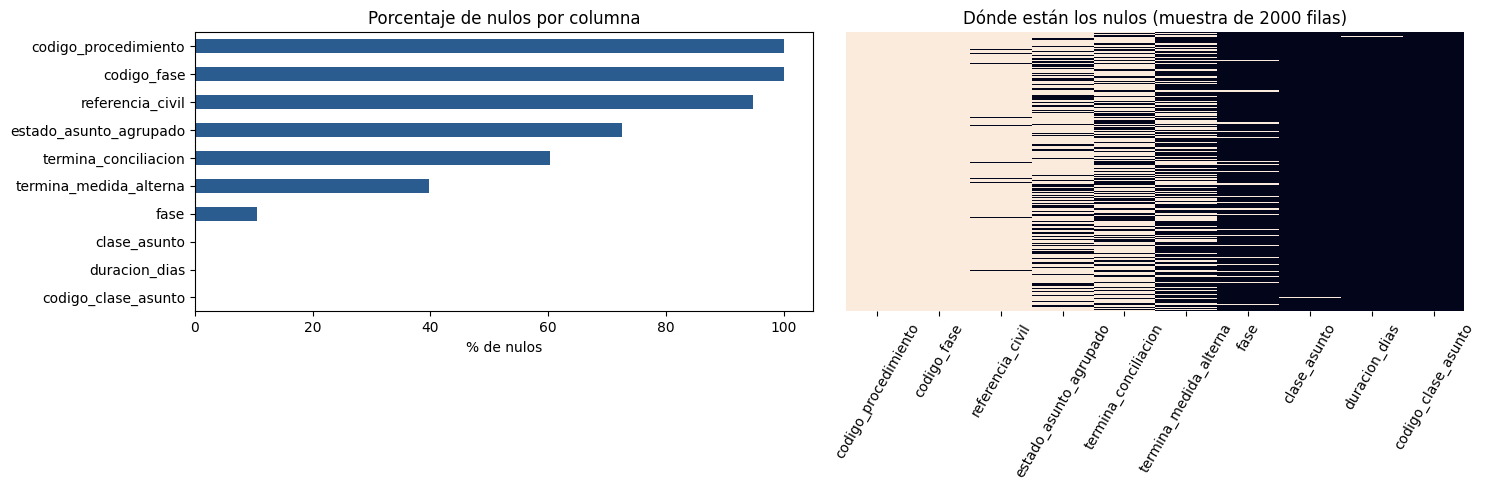

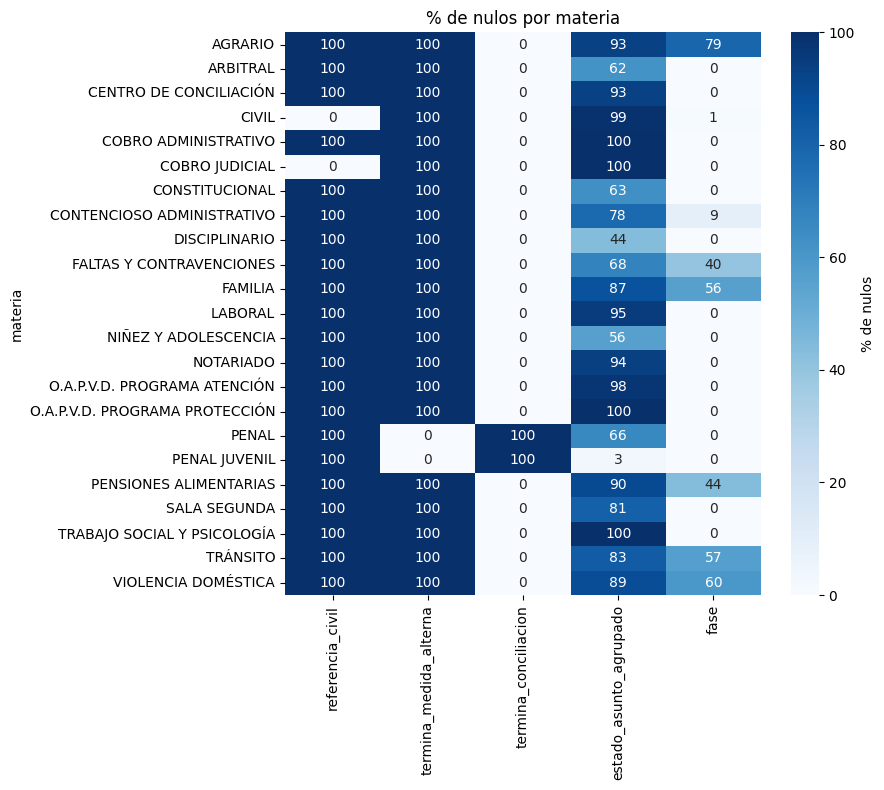

In [13]:
# 2.1 VALORES NULOS (reales y disfrazados de texto)
VALORES_TIPO_NULO = ["", "NA", "N/A", "NULL", "NONE", "NAN", "-",
                     "SIN DATO", "NO APLICA", "DESCONOCIDO", "IGNORADO"]

def resumen_nulos(datos):
    """Cantidad y porcentaje de nulos de cada columna."""
    tabla = pd.DataFrame({"nulos": datos.isna().sum(),
                          "porcentaje": (datos.isna().mean() * 100).round(2)})
    return tabla.sort_values("nulos", ascending=False)

def buscar_nulos_disfrazados(datos):
    """Busca textos que funcionan como nulo (ej. 'DESCONOCIDO') en columnas de texto."""
    filas = []
    for col in datos.select_dtypes(exclude="number").columns:
        texto = datos[col].astype("string").str.strip().str.upper()
        for valor in VALORES_TIPO_NULO:
            n = int((texto == valor).sum())
            if n > 0:
                filas.append([col, valor, n, round(n / len(datos) * 100, 2)])
    return (pd.DataFrame(filas, columns=["columna", "valor", "cantidad", "porcentaje"])
              .sort_values("cantidad", ascending=False).reset_index(drop=True))

def graficar_nulos(datos):
    """Barras con el % de nulos y mapa de calor de dónde están."""
    tabla = resumen_nulos(datos)
    tabla = tabla[tabla["nulos"] > 0]
    if tabla.empty:
        print("No hay valores nulos.")
        return
    fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
    tabla["porcentaje"].sort_values().plot(kind="barh", ax=ejes[0], color="#2b5c8f")
    ejes[0].set_title("Porcentaje de nulos por columna")
    ejes[0].set_xlabel("% de nulos")
    muestra = datos[tabla.index].sample(2000, random_state=1)  # muestra para que no sea pesado
    sns.heatmap(muestra.isna(), cbar=False, yticklabels=False, ax=ejes[1])
    ejes[1].set_title("Dónde están los nulos (muestra de 2000 filas)")
    ejes[1].tick_params(axis="x", rotation=60)
    plt.tight_layout()
    plt.show()

def nulos_por_grupo(datos, columnas, grupo):
    """% de nulos de cada columna dentro de cada grupo (para ver si dependen de la materia)."""
    return datos.groupby(grupo)[columnas].apply(lambda g: (g.isna().mean() * 100).round(0))

def graficar_nulos_por_grupo(datos, columnas, grupo):
    """Mapa de calor del % de nulos por grupo: muestra si los nulos son estructurales."""
    tabla = nulos_por_grupo(datos, columnas, grupo)
    plt.figure(figsize=(9, 8))
    sns.heatmap(tabla, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% de nulos"})
    plt.title(f"% de nulos por {grupo}")
    plt.tight_layout()
    plt.show()

print(resumen_nulos(df))
print(buscar_nulos_disfrazados(df))
print("Registros duplicados:", df.duplicated().sum())
graficar_nulos(df)
graficar_nulos_por_grupo(df, ["referencia_civil", "termina_medida_alterna", "termina_conciliacion",
                              "estado_asunto_agrupado", "fase"], "materia")

**Hallazgos de valores nulos**

El conjunto tiene 309 635 filas y 23 columnas originales, sin registros duplicados.

- `codigo_procedimiento` y `codigo_fase` están 100 % vacías. Les siguen `referencia_civil` (94.8 %), `estado_asunto_agrupado` (72.5 %), `termina_conciliacion` (60.3 %), `termina_medida_alterna` (39.7 %) y `fase` (10.6 %). `clase_asunto` (597), `duracion_dias` (273) y `codigo_clase_asunto` (54) tienen muy pocos.
- El mapa de calor por materia muestra que la mayoría de esos nulos son estructurales: la columna solo aplica a ciertas materias (por ejemplo, `termina_medida_alterna` solo tiene datos en PENAL y PENAL JUVENIL, y `referencia_civil` solo en CIVIL y COBRO JUDICIAL).
- Hay nulos disfrazados de texto: `delito` tiene "DESCONOCIDO" (25.6 %), "IGNORADO" (2.8 %) y "NO APLICA" (1.4 %); `procedimiento` tiene "DESCONOCIDO" (1.4 %) y "-" (0.2 %).
- Evidencia: gráfico de barras, mapa de calor de la muestra y mapa de calor por materia.

             columna  inferiores  superiores  total  porcentaje
0      duracion_dias           0        1541   1541        0.50
1           cantidad           0       27769  27769        8.97
2  duracion_promedio           0           1      1        0.00
             columna  inferiores  superiores  total  porcentaje
0      duracion_dias        1878         304   2182        0.70
1           cantidad           0       25733  25733        8.31
2  duracion_promedio        2167         123   2290        0.74


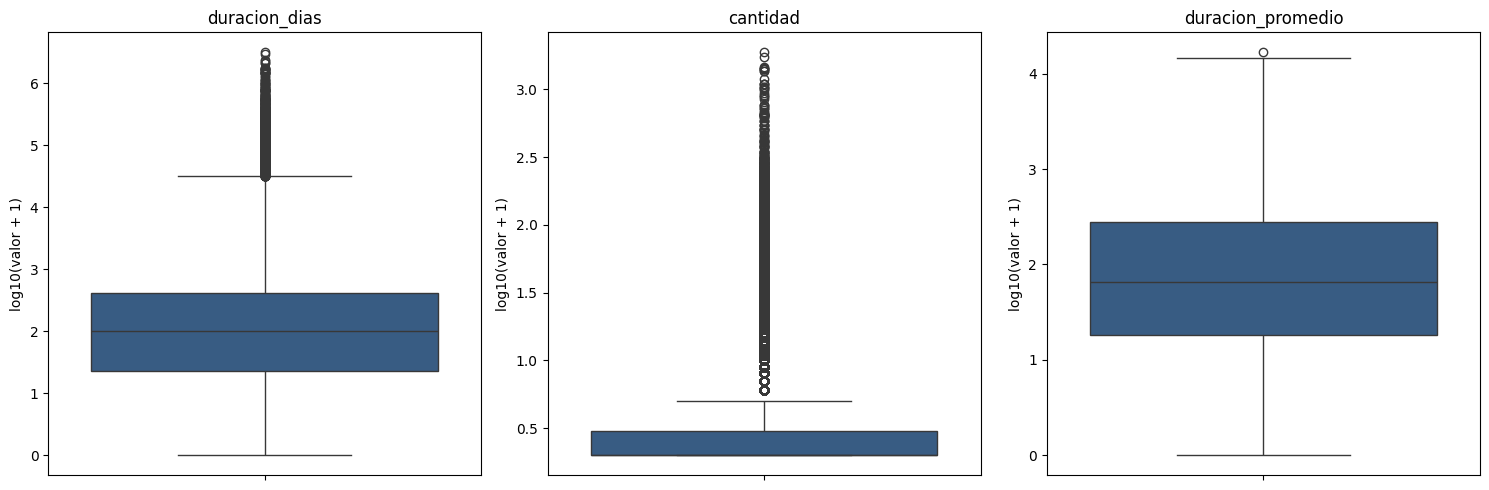

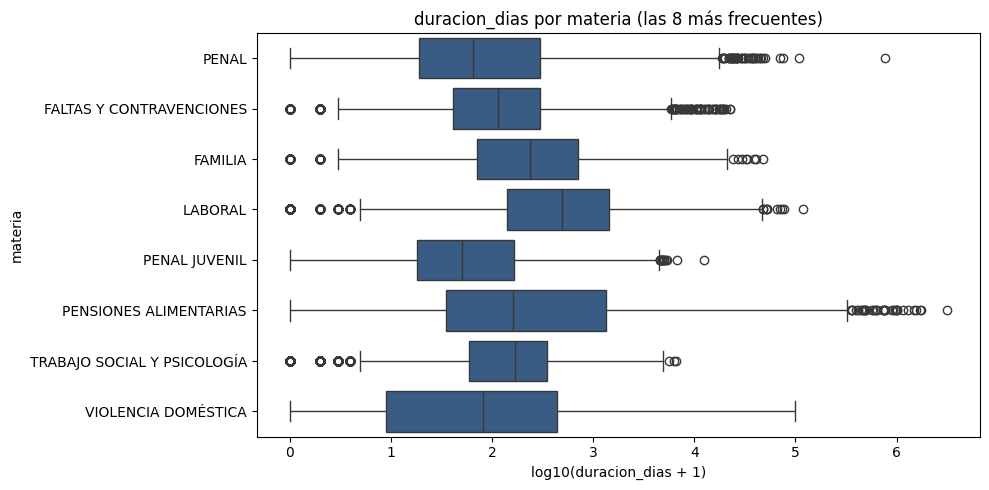

In [14]:
# 2.2 VALORES ATÍPICOS
# duracion_dias es una suma de días de varios expedientes; se crea el promedio por expediente
df["duracion_promedio"] = df["duracion_dias"] / df["cantidad"]

def limites_iqr(serie, usar_log=False):
    """
    Límites inferior y superior con la regla 1.5 x IQR.
    Con usar_log=True se calculan sobre log10(x + 1), porque las duraciones
    tienen una cola muy larga (igual que se hizo con log_total en el taller de R).
    """
    valores = serie.dropna()
    if usar_log:
        valores = np.log10(valores + 1)
    q1, q3 = valores.quantile(0.25), valores.quantile(0.75)
    iqr = q3 - q1
    inf, sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    if usar_log:
        inf, sup = 10 ** inf - 1, 10 ** sup - 1
    return max(inf, 0), sup   # una duración no puede ser negativa

def marcar_atipicos(datos, columna, usar_log=False, grupo=None, tipo="ambos", min_grupo=30):
    """
    True en cada registro atípico (tipo: 'inferior', 'superior' o 'ambos').
    Con grupo, cada categoría usa sus propios límites; los grupos con menos de min_grupo
    registros usan el límite general, porque con tan pocos datos el IQR no es confiable.
    """
    limite_general = limites_iqr(datos[columna], usar_log)
    def marcar(s):
        inf, sup = limites_iqr(s, usar_log) if s.notna().sum() >= min_grupo else limite_general
        if tipo == "inferior":
            return s < inf
        if tipo == "superior":
            return s > sup
        return (s < inf) | (s > sup)
    if grupo is None:
        return marcar(datos[columna])
    return datos.groupby(grupo)[columna].transform(marcar).astype(bool)

def resumen_atipicos(datos, columnas, usar_log=False, grupo=None):
    """Cantidad de atípicos inferiores y superiores de cada columna."""
    filas = []
    for col in columnas:
        bajos = int(marcar_atipicos(datos, col, usar_log, grupo, "inferior").sum())
        altos = int(marcar_atipicos(datos, col, usar_log, grupo, "superior").sum())
        filas.append([col, bajos, altos, bajos + altos, round((bajos + altos) / len(datos) * 100, 2)])
    return pd.DataFrame(filas, columns=["columna", "inferiores", "superiores", "total", "porcentaje"])

def graficar_atipicos(datos, columnas, grupo=None, top=8):
    """Diagrama de caja de cada medida y, si hay grupo, por categoría (las más frecuentes)."""
    fig, ejes = plt.subplots(1, len(columnas), figsize=(5 * len(columnas), 5))
    for ax, col in zip(np.atleast_1d(ejes), columnas):
        sns.boxplot(y=np.log10(datos[col] + 1), ax=ax, color="#2b5c8f")
        ax.set_title(col)
        ax.set_ylabel("log10(valor + 1)")
    plt.tight_layout()
    plt.show()
    if grupo is not None:
        principales = datos[grupo].value_counts().head(top).index
        sub = datos[datos[grupo].isin(principales)]
        plt.figure(figsize=(10, 5))
        sns.boxplot(data=sub, y=grupo, x=np.log10(sub[columnas[0]] + 1), color="#2b5c8f")
        plt.xlabel(f"log10({columnas[0]} + 1)")
        plt.title(f"{columnas[0]} por {grupo} (las {top} más frecuentes)")
        plt.tight_layout()
        plt.show()

columnas_medidas = ["duracion_dias", "cantidad", "duracion_promedio"]
print(resumen_atipicos(df, columnas_medidas, usar_log=True))                    # un límite general
print(resumen_atipicos(df, columnas_medidas, usar_log=True, grupo="materia"))   # un límite por materia
graficar_atipicos(df, columnas_medidas, grupo="materia")

## Hallazgos de valores atípicos

- Se analizaron `duracion_dias`, `cantidad` y `duracion_promedio` (los códigos y el mes no son medidas). Se usó la regla 1.5 × IQR sobre el logaritmo (la cola es muy larga) y un límite por materia (las duraciones varían mucho entre materias).
- Con un límite general casi no se detectan atípicos en `duracion_promedio` (1 registro). Por materia son 2 290: 2 167 inferiores y 123 superiores.
- Los inferiores son duraciones muy cortas (cerca de 980 son de 0 días), que son válidas: un asunto puede cerrarse el mismo día. Los superiores sí son expedientes de duración extrema.
- `cantidad` tiene 25 733 atípicos superiores (8.3 %); son grupos grandes reales.
- Evidencia: diagramas de caja generales y por materia.

In [15]:
# 2.3 FUNCIONES DE IMPUTACIÓN Y TRATAMIENTO

def eliminar_columnas_vacias(datos):
    """
    Elimina las columnas que están 100% vacías.
    Justificación: no tienen ningún dato que analizar ni imputar.
    """
    vacias = [c for c in datos.columns if datos[c].isna().all()]
    print("Columnas vacías eliminadas:", vacias)
    return datos.drop(columns=vacias)

def unificar_desconocidos(datos, columnas, equivalentes=("-", "IGNORADO", "SIN DATO")):
    """
    Une en 'DESCONOCIDO' los textos que funcionan como nulo y significan lo mismo
    ('-', 'IGNORADO', 'SIN DATO').
    Justificación: se conservan como categoría (no se borran ni se rellenan con la moda)
    porque son una respuesta real del sistema. 'NO APLICA' se deja aparte: significa otra cosa.
    """
    datos = datos.copy()
    for col in columnas:
        texto = datos[col].astype("string").str.strip().str.upper()
        datos.loc[texto.isin(equivalentes), col] = "DESCONOCIDO"
    return datos

def recuperar_clase_por_codigo(datos):
    """
    Recupera la descripción de la clase de asunto a partir de su código (la más frecuente).
    Justificación: es una recuperación exacta desde datos del mismo archivo, no una estimación.
    """
    datos = datos.copy()
    mapa = (datos.dropna(subset=["clase_asunto"]).groupby("codigo_clase_asunto")["clase_asunto"]
            .agg(lambda s: s.mode().iloc[0]))
    faltan = datos["clase_asunto"].isna() & datos["codigo_clase_asunto"].notna()
    datos.loc[faltan, "clase_asunto"] = datos.loc[faltan, "codigo_clase_asunto"].map(mapa)
    print("Descripciones recuperadas desde el código:", int((faltan & datos["clase_asunto"].notna()).sum()))
    return datos

def imputar_categoricas(datos, reglas):
    """
    Rellena nulos de texto con una etiqueta por columna (diccionario columna -> texto).
    Justificación: la mayoría de los nulos son ESTRUCTURALES (la columna no aplica a esa
    materia), así que la moda inventaría datos; una etiqueta propia los conserva y los distingue.
    """
    datos = datos.copy()
    for col, texto in reglas.items():
        if col in datos.columns:
            datos[col] = datos[col].fillna(texto)
    return datos

def imputar_duracion(datos):
    """
    Rellena los nulos de duracion_dias así: mediana de la duración PROMEDIO de su materia
    y su completitud, multiplicada por la cantidad de expedientes de la fila.
    Justificación: duracion_dias es una suma, por eso se estima el promedio y se multiplica;
    la completitud se usa porque separa duraciones muy distintas (mediana de 60 vs 2 195 días).
    Se marca con 'duracion_imputada' qué filas se rellenaron.
    """
    datos = datos.copy()
    promedio = datos["duracion_dias"] / datos["cantidad"]
    mediana_fina = promedio.groupby([datos["materia"], datos["completitud"]]).transform("median")
    mediana_materia = promedio.groupby(datos["materia"]).transform("median")
    estimado = promedio.fillna(mediana_fina).fillna(mediana_materia).fillna(promedio.median())
    datos["duracion_imputada"] = datos["duracion_dias"].isna()
    datos["duracion_dias"] = datos["duracion_dias"].fillna(estimado * datos["cantidad"])
    print("Duraciones imputadas:", int(datos["duracion_imputada"].sum()))
    return datos

def topar_atipicos(datos, columna, columna_nueva, usar_log=False, grupo=None,
                   tipo="superior", min_grupo=30):
    """
    Recorta los atípicos al límite 1.5 x IQR de su grupo en una columna nueva.
    Por defecto solo el lado SUPERIOR: una duración corta (incluso 0 días) es válida, mientras
    que las muy largas son las que distorsionan. Se conservan todos los registros.
    """
    datos = datos.copy()
    limite_general = limites_iqr(datos[columna], usar_log)
    def topar(s):
        inf, sup = limites_iqr(s, usar_log) if s.notna().sum() >= min_grupo else limite_general
        return s.clip(lower=inf if tipo != "superior" else None,
                      upper=sup if tipo != "inferior" else None)
    if grupo is None:
        datos[columna_nueva] = topar(datos[columna])
    else:
        datos[columna_nueva] = datos.groupby(grupo)[columna].transform(topar)
    print(f"Valores recortados en {columna_nueva}:", int((datos[columna_nueva] != datos[columna]).sum()))
    return datos

REGLAS_CATEGORICAS = {
    "referencia_civil": "NO APLICA",
    "termina_medida_alterna": "NO APLICA",
    "termina_conciliacion": "NO APLICA",
    "estado_asunto_agrupado": "SIN AGRUPAR",
    "fase": "SIN FASE",
    "codigo_clase_asunto": "DESCONOCIDO",
    "clase_asunto": "DESCONOCIDO",
}

df_limpio = eliminar_columnas_vacias(df.drop(columns=["duracion_promedio"]))
df_limpio = unificar_desconocidos(df_limpio, ["delito", "procedimiento"])
df_limpio = recuperar_clase_por_codigo(df_limpio)
df_limpio = imputar_categoricas(df_limpio, REGLAS_CATEGORICAS)
df_limpio = imputar_duracion(df_limpio)
df_limpio["duracion_promedio"] = df_limpio["duracion_dias"] / df_limpio["cantidad"]
df_limpio = topar_atipicos(df_limpio, "duracion_promedio", "duracion_promedio_ajustada",
                           usar_log=True, grupo="materia")
# cantidad y duracion_dias NO se recortan (ver documentación)

print("Nulos totales:", int(df_limpio.isna().sum().sum()), "| Forma:", df_limpio.shape)

Columnas vacías eliminadas: ['codigo_procedimiento', 'codigo_fase']
Descripciones recuperadas desde el código: 502
Duraciones imputadas: 273
Valores recortados en duracion_promedio_ajustada: 124
Nulos totales: 0 | Forma: (309635, 24)


## Decisiones de limpieza e imputación
1. **Columnas vacías.** Se eliminaron `codigo_procedimiento` y `codigo_fase` (100 % vacías): no hay datos que analizar.

2. **Nulos estructurales: etiqueta, no moda.** Según el mapa de calor, la mayoría de los nulos ocurren porque la columna no aplica a la materia. `termina_medida_alterna`, `termina_conciliacion` y `referencia_civil` se rellenaron con "NO APLICA" (en `referencia_civil`, "NO" habría sido falso). `estado_asunto_agrupado` se rellenó con "SIN AGRUPAR" y `fase` con "SIN FASE". Se evitó la moda porque inventaría información.

3. **Nulos disfrazados.** "IGNORADO" y "-" se unieron con "DESCONOCIDO" en `delito` y `procedimiento`. Se conservan como categoría porque son una respuesta real del sistema (`delito` queda con 28.5 % en "DESCONOCIDO"). "NO APLICA" se dejó aparte porque significa otra cosa.

4. **`clase_asunto`.** De 597 nulos, 502 se recuperaron con su `codigo_clase_asunto` (la descripción más frecuente de ese código). Es una recuperación exacta desde el mismo archivo. Los 95 restantes quedaron como "DESCONOCIDO".

5. **Por qué se creó `duracion_promedio`.** No hay diccionario de datos que explique `duracion_dias`. Al compararla con `cantidad`, su mediana crece casi proporcional (65 días con 1 expediente, 127 con 2, 220 con 3 a 5, 437 con 6 a 10, 1 222 con 11 a 50), mientras que la duración por expediente se mantiene entre 60 y 68. Se concluye que es una suma. Es una interpretación basada en los datos, no confirmada oficialmente.

6. **Nulos de `duracion_dias` (273 filas, 0.09 %).** No son aleatorios: afectan al 0.53 % de los casos INCOMPLETA y al 0.07 % de los COMPLETA. Se rellenaron con la mediana de la duración promedio de su materia y su completitud, multiplicada por su `cantidad`. Se usó la completitud porque separa duraciones muy distintas (mediana de 60 días en COMPLETA y de 2 195 en INCOMPLETA). La columna `duracion_imputada` marca esas filas.

7. **Atípicos: solo se recortó el lado superior.** Los inferiores son duraciones cortas válidas, así que no se tocaron. Los 124 valores superiores de `duracion_promedio` se recortaron al límite de su materia en la columna nueva `duracion_promedio_ajustada`: así se conservan todos los registros y la columna original no cambia. Las materias con menos de 30 registros usan el límite general, porque con tan pocos datos el IQR no es confiable.

8. **Lo que no se recortó.** `cantidad`, porque los grupos grandes son reales y recortarla cambiaría el 8.3 % de los datos. `duracion_dias`, porque sus valores altos se explican por la cantidad de expedientes (los atípicos superiores de la suma tienen una `cantidad` mediana de 116, contra 1 en el resto), no por errores.

9. **Limitaciones.** Las medianas y límites se calcularon con todo el conjunto; en un modelo real deberían calcularse solo con los datos de entrenamiento. La columna `completitud` está muy ligada a la duración: INCOMPLETA es el 3 % de las filas, pero concentra las duraciones más extremas.

---
## 3. Transformación (Dylan)

Se trabaja sobre `df_limpio`, que sale de la sección 2 (sin nulos, 309 635 filas y 24 columnas). Los pasos son:

- [x] 3.1 Corregir tipos de datos
- [x] 3.2 Convertir variables categóricas a numéricas
- [x] 3.3 Normalización o estandarización

Al final quedan dos DataFrames para la sección 4:
- `df_transformado`: todo numérico, con las medidas en sus unidades originales (días, expedientes).
- `df_escalado`: lo mismo, pero con las medidas estandarizadas. Es el que se guarda como `data_process.csv`.

### 3.1 Corrección de tipos de datos

Antes de cambiar los tipos se revisó cómo vienen escritas las categorías. Hay valores iguales escritos de varias formas, por ejemplo `Circuito Judicial de Heredia` y `CIRCUITO JUDICIAL DE HEREDIA`, o `Conclusiva`, `CONCLUSIVA` y `Conclusiva ` (con espacio al final). Si no se unifican, al convertirlas a números cada forma contaría como una categoría distinta.

In [16]:
# 3.1 CORRECCIÓN DE TIPOS DE DATOS
import unicodedata

COLUMNAS_CODIGO = ["codigo_circuito", "codigo_despacho", "codigo_clase_asunto"]

def quitar_tildes(texto):
    """'CONCLUSIÓN' -> 'CONCLUSION'."""
    return "".join(c for c in unicodedata.normalize("NFKD", texto) if not unicodedata.combining(c))

def normalizar_texto(datos):
    """
    Pasa las columnas de texto a mayúscula, sin tildes y sin espacios de más.
    Justificación: la misma categoría viene escrita de varias formas (mayúsculas, tildes,
    espacios dobles). Unificarlas evita que una misma categoría se cuente varias veces.
    Devuelve el DataFrame y una tabla con cuántas categorías se unieron por columna.
    """
    datos = datos.copy()
    filas = []
    for col in datos.select_dtypes(include=["object", "string"]).columns:
        antes = datos[col].nunique()
        texto = (datos[col].astype(str).str.strip().str.upper()
                 .str.replace(r"\s+", " ", regex=True))
        mapa = {valor: quitar_tildes(valor) for valor in texto.unique()}  # solo valores únicos: más rápido
        datos[col] = texto.map(mapa)
        filas.append([col, antes, datos[col].nunique()])
    tabla = pd.DataFrame(filas, columns=["columna", "categorias_antes", "categorias_despues"])
    tabla["unidas"] = tabla["categorias_antes"] - tabla["categorias_despues"]
    return datos, tabla.sort_values("unidas", ascending=False).reset_index(drop=True)

def eliminar_constantes(datos):
    """
    Elimina las columnas que tienen un solo valor.
    Justificación: `anio` vale 2026 en todas las filas, así que no distingue un registro de otro.
    Además su desviación estándar es 0 y al estandarizarla se dividiría entre 0.
    """
    constantes = [c for c in datos.columns if datos[c].nunique() <= 1]
    print("Columnas constantes eliminadas:", constantes)
    return datos.drop(columns=constantes)

def corregir_tipos(datos):
    """
    Asigna a cada columna el tipo que le corresponde.
    Justificación:
    - Códigos -> category: `codigo_circuito` y `codigo_despacho` se leyeron como enteros, pero son
      etiquetas (sumar o promediar códigos de despacho no tiene sentido). `codigo_clase_asunto`
      ya era texto para no perder los ceros a la izquierda.
    - Texto -> category: son pocas categorías que se repiten muchas veces; ocupa menos memoria y
      deja claro que son variables categóricas.
    - mes -> int8 y cantidad -> int32: son enteros pequeños (mes 1-9, cantidad máx. 1 871).
    - duracion_dias se queda como float: 155 valores imputados tienen decimales.
    - duracion_imputada ya es bool (True/False).
    """
    datos = datos.copy()
    for col in COLUMNAS_CODIGO:
        datos[col] = datos[col].astype(str).astype("category")
    for col in datos.select_dtypes(include=["object", "string"]).columns:
        datos[col] = datos[col].astype("category")
    datos["mes"] = datos["mes"].astype("int8")
    datos["cantidad"] = datos["cantidad"].astype("int32")
    datos["duracion_dias"] = datos["duracion_dias"].astype("float64")
    datos["duracion_promedio"] = datos["duracion_promedio"].astype("float64")
    datos["duracion_promedio_ajustada"] = datos["duracion_promedio_ajustada"].astype("float64")
    return datos

tipos_antes = df_limpio.dtypes.astype(str)
memoria_antes = df_limpio.memory_usage(deep=True).sum() / 1e6

df_tipos, tabla_texto = normalizar_texto(df_limpio)
df_tipos = eliminar_constantes(df_tipos)
df_tipos = corregir_tipos(df_tipos)

memoria_despues = df_tipos.memory_usage(deep=True).sum() / 1e6

print("\nCategorías unidas al normalizar el texto:")
print(tabla_texto[tabla_texto["unidas"] > 0].to_string(index=False))

print("\nTipos antes y después:")
print(pd.DataFrame({"antes": tipos_antes, "despues": df_tipos.dtypes.astype(str)}).fillna("(eliminada)"))
print(f"\nMemoria: {memoria_antes:,.1f} MB -> {memoria_despues:,.1f} MB")

Columnas constantes eliminadas: ['anio']

Categorías unidas al normalizar el texto:
      columna  categorias_antes  categorias_despues  unidas
         fase               132                 113      19
       delito               634                 619      15
procedimiento               568                 555      13
     circuito                79                  73       6
 clase_asunto               618                 613       5
tipo_despacho                71                  68       3

Tipos antes y después:
                              antes      despues
anio                          int64  (eliminada)
cantidad                      int64        int32
circuito                     object     category
clase_asunto                 object     category
codigo_circuito               int64     category
codigo_clase_asunto          object     category
codigo_despacho               int64     category
completitud                  object     category
delito                       ob

**Decisiones de tipos de datos**

1. **Texto unificado.** Se pasó todo a mayúscula, sin tildes y sin espacios de más. Así se unieron categorías repetidas, por ejemplo en `fase` (de 132 a 113), `delito`, `procedimiento` y `circuito` (la tabla de arriba muestra cuántas por columna). No se corrigieron errores de ortografía como `INCOMPENTENCIA`, porque no se puede saber con seguridad cuáles son errores sin un diccionario de datos.
2. **`anio` eliminada.** Tiene un solo valor (2026), así que no aporta información y no se puede estandarizar.
3. **Códigos como categoría.** `codigo_circuito` y `codigo_despacho` venían como enteros, pero son identificadores. Si se dejaran como números, un modelo podría interpretar que el despacho 1 500 es "mayor" que el 300.
4. **Texto como `category`.** Las columnas de texto se pasaron a `category`, lo que reduce mucho la memoria (ver arriba) y prepara la conversión a números del siguiente paso.
5. **Enteros más pequeños.** `mes` pasa a `int8` y `cantidad` a `int32`. Las duraciones se quedan como `float64`.

### 3.2 Conversión de variables categóricas a numéricas

Se usó una técnica distinta según la cantidad de categorías de cada columna:

| Técnica | Columnas | Por qué |
|---|---|---|
| Binaria (0/1) | `completitud`, `referencia_civil`, `duracion_imputada` | Solo tienen 2 valores |
| One-hot (una columna 0/1 por categoría) | `materia` (23), `termina_medida_alterna` (3), `termina_conciliacion` (3) | Pocas categorías y sin orden entre ellas |
| Frecuencia (proporción de filas con esa categoría) | `circuito`, `tipo_despacho`, `despacho`, `clase_asunto`, `procedimiento`, `estado_asunto`, `estado_asunto_agrupado`, `fase`, `delito` | Entre 40 y 900 categorías cada una |
| Se eliminan | `codigo_circuito`, `codigo_despacho`, `codigo_clase_asunto` | Repiten la información de su descripción |

In [17]:
# 3.2 CONVERSIÓN DE VARIABLES CATEGÓRICAS A NUMÉRICAS

BINARIAS = {
    "completitud": {"COMPLETA": 0, "INCOMPLETA": 1},
    "referencia_civil": {"NO APLICA": 0, "SI": 1},
}
ONE_HOT = ["materia", "termina_medida_alterna", "termina_conciliacion"]
FRECUENCIA = ["circuito", "tipo_despacho", "despacho", "clase_asunto", "procedimiento",
              "estado_asunto", "estado_asunto_agrupado", "fase", "delito"]

def nombre_columna(texto):
    """'materia_PENAL JUVENIL' -> 'materia_penal_juvenil' (mismo estilo que el resto de columnas)."""
    return "_".join(str(texto).lower().replace("/", " ").replace("-", " ").replace(".", " ").split())

def codificar_binarias(datos, reglas):
    """
    Cambia las columnas de 2 valores por 0 y 1 según el diccionario de reglas.
    Justificación: con dos valores basta una sola columna; el 1 indica el caso menos común
    (INCOMPLETA, SI). duracion_imputada pasa de True/False a 1/0.
    """
    datos = datos.copy()
    for col, mapa in reglas.items():
        datos[col] = datos[col].astype(str).map(mapa).astype("int8")
    datos["duracion_imputada"] = datos["duracion_imputada"].astype("int8")
    return datos

def codificar_one_hot(datos, columnas):
    """
    Crea una columna 0/1 por cada categoría.
    Justificación: las materias y los valores SI / NO / NO APLICA no tienen un orden, así que
    numerarlos (0, 1, 2...) inventaría uno. Con pocas categorías, one-hot no agrega
    demasiadas columnas. Se conservan todas las categorías (no se usa drop_first) para que la
    sección 4 pueda ver la correlación de cada una; en un modelo lineal se debe quitar una por variable.
    """
    dummies = pd.get_dummies(datos[columnas], prefix=columnas, dtype="int8")
    dummies.columns = [nombre_columna(c) for c in dummies.columns]
    print(f"One-hot: {len(columnas)} columnas -> {dummies.shape[1]} columnas 0/1")
    return pd.concat([datos.drop(columns=columnas), dummies], axis=1)

def codificar_frecuencia(datos, columnas):
    """
    Cambia cada categoría por la proporción de filas que la tienen (columna nueva *_frec).
    Justificación: estas columnas tienen entre 40 y 900 categorías.
    - One-hot crearía miles de columnas casi vacías.
    - Numerarlas (label encoding) inventaría un orden alfabético que no existe.
    - Codificarlas con la duración promedio (target encoding) filtraría la variable que se
      quiere predecir.
    La frecuencia da una sola columna numérica sin inventar un orden. Indica si la categoría es
    común (por ejemplo, despachos con mucho volumen) o rara.
    Limitación: dos categorías con la misma frecuencia quedan con el mismo valor.
    Devuelve el DataFrame y los mapas categoría -> frecuencia, para poder aplicarlos a datos nuevos.
    """
    datos = datos.copy()
    mapas, filas = {}, []
    for col in columnas:
        texto = datos[col].astype(str)
        mapa = texto.value_counts(normalize=True)
        datos[col + "_frec"] = texto.map(mapa).astype("float64")
        mapas[col] = mapa
        filas.append([col, len(mapa), datos[col + "_frec"].nunique()])
    print(pd.DataFrame(filas, columns=["columna", "categorias", "valores_distintos_frec"]).to_string(index=False))
    return datos.drop(columns=columnas), mapas

df_transformado = df_tipos.drop(columns=COLUMNAS_CODIGO)   # redundantes con su descripción
df_transformado = codificar_binarias(df_transformado, BINARIAS)
df_transformado = codificar_one_hot(df_transformado, ONE_HOT)
df_transformado, mapas_frecuencia = codificar_frecuencia(df_transformado, FRECUENCIA)

no_numericas = df_transformado.select_dtypes(exclude="number").columns.tolist()
print("\nColumnas que no son numéricas:", no_numericas if no_numericas else "ninguna")
print("Forma:", df_transformado.shape, "| Nulos:", int(df_transformado.isna().sum().sum()))
df_transformado.head()

One-hot: 3 columnas -> 29 columnas 0/1
               columna  categorias  valores_distintos_frec
              circuito          73                      73
         tipo_despacho          68                      66
              despacho         907                     502
          clase_asunto         613                     237
         procedimiento         555                     213
         estado_asunto         642                     285
estado_asunto_agrupado          46                      44
                  fase         113                      88
                delito         619                     236

Columnas que no son numéricas: ninguna
Forma: (309635, 46) | Nulos: 0


,mes,cantidad,duracion_dias,completitud,referencia_civil,duracion_imputada,duracion_promedio,duracion_promedio_ajustada,materia_agrario,materia_arbitral,materia_centro_de_conciliacion,materia_civil,materia_cobro_administrativo,materia_cobro_judicial,materia_constitucional,materia_contencioso_administrativo,materia_disciplinario,materia_faltas_y_contravenciones,materia_familia,materia_laboral,materia_ninez_y_adolescencia,materia_notariado,materia_o_a_p_v_d_programa_atencion,materia_o_a_p_v_d_programa_proteccion,materia_penal,materia_penal_juvenil,materia_pensiones_alimentarias,materia_sala_segunda,materia_trabajo_social_y_psicologia,materia_transito,materia_violencia_domestica,termina_medida_alterna_no,termina_medida_alterna_no_aplica,termina_medida_alterna_si,termina_conciliacion_no,termina_conciliacion_no_aplica,termina_conciliacion_si,circuito_frec,tipo_despacho_frec,despacho_frec,clase_asunto_frec,procedimiento_frec,estado_asunto_frec,estado_asunto_agrupado_frec,fase_frec,delito_frec
0,3,1,615.00,0,0,0,615.00,615.00,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0.04,0.27,0.01,0.12,0.50,0.05,0.06,0.20,0.01
1,3,1,0.00,0,0,0,0.00,0.00,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0.04,0.27,0.01,0.12,0.50,0.02,0.72,0.20,0.00
2,3,1,"1,409.00",0,0,0,"1,409.00","1,409.00",0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0.04,0.27,0.01,0.12,0.50,0.02,0.72,0.20,0.00
3,3,1,10.00,0,0,0,10.00,10.00,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0.04,0.27,0.01,0.12,0.50,0.02,0.72,0.20,0.02
4,3,1,16.00,0,0,0,16.00,16.00,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0.04,0.27,0.01,0.12,0.50,0.06,0.72,0.16,0.00


**Decisiones de la conversión a números**

1. **Binarias.** `completitud` (INCOMPLETA = 1) y `referencia_civil` (SI = 1) quedan como 0/1. En `referencia_civil`, el 0 significa "no aplica", no "no": ese valor no existe en los datos (ver sección 2).
2. **One-hot.** `materia` genera 23 columnas. `termina_medida_alterna` y `termina_conciliacion` generan 3 cada una (`si`, `no`, `no_aplica`). Se usó one-hot porque no tienen orden: decir que PENAL = 2 y LABORAL = 1 sería falso.
3. **Frecuencia para las de muchas categorías.** Aplicar one-hot a las nueve columnas grandes crearía más de 3 500 columnas. El label encoding inventaría un orden. El target encoding (promedio de la duración por categoría) se descartó porque usa la variable que probablemente se quiera predecir. La tabla muestra la limitación: las categorías poco comunes con la misma cantidad de filas comparten valor (por ejemplo, `despacho` pasa de 907 categorías a 502 valores distintos). Se aceptó porque esas categorías quedan agrupadas como "raras", que es justamente lo que mide esta codificación.
4. **Códigos eliminados.** `codigo_circuito`, `codigo_despacho` y `codigo_clase_asunto` repiten la información de `circuito`, `despacho` y `clase_asunto`, que ya están codificadas. Dejarlas duplicaría variables en la correlación.
5. **Resultado.** `df_transformado` es 100 % numérico y no tiene nulos. Las medidas siguen en días y en cantidad de expedientes.

### 3.3 Estandarización

Las variables numéricas están en escalas muy distintas: `mes` va de 1 a 9, las frecuencias de 0 a 1 y `duracion_dias` llega a más de 3 millones. Los modelos basados en distancias o en coeficientes (regresión, KNN, SVM) le darían más peso a la variable con números más grandes. Por eso se llevan todas a la misma escala.

Se eligió **estandarización (z-score)**, aplicando antes un **logaritmo** a las medidas con cola larga. La celda siguiente muestra por qué no se usó normalización min-max.

In [18]:
# 3.3 ESTANDARIZACIÓN
from sklearn.preprocessing import StandardScaler

# Medidas con cola muy larga (ver sección 2.2): se les aplica log(x + 1) antes de estandarizar
COLUMNAS_LOG = ["cantidad", "duracion_dias", "duracion_promedio", "duracion_promedio_ajustada"]

def columnas_a_escalar(datos):
    """
    Columnas numéricas con más de 2 valores.
    Justificación: las columnas 0/1 (binarias y one-hot) ya están en la misma escala y se
    entienden como "sí / no"; estandarizarlas solo haría más difícil interpretarlas.
    """
    return [c for c in datos.select_dtypes(include="number").columns if datos[c].nunique() > 2]

def estandarizar(datos, columnas, columnas_log):
    """
    Aplica log(x + 1) a las medidas con cola larga y luego z = (x - media) / desviación estándar.
    Justificación:
    - Logaritmo: las duraciones y la cantidad están muy sesgadas (media 323 y mediana 65 días en
      duracion_promedio). Sin el log, la media y la desviación las dominarían los valores extremos.
      Se usa log(x + 1) porque hay duraciones de 0 días.
    - Z-score: deja cada columna con media 0 y desviación 1, así que todas pesan lo mismo.
    Devuelve el DataFrame y el escalador, por si se necesita volver a las unidades originales.
    """
    datos = datos.copy()
    for col in columnas_log:
        datos[col] = np.log1p(datos[col])
    escalador = StandardScaler()
    datos[columnas] = escalador.fit_transform(datos[columnas])
    return datos, escalador

# Por qué no min-max: con un máximo tan extremo, casi todos los valores quedan pegados a 0
serie = df_transformado["duracion_dias"]
minmax = (serie - serie.min()) / (serie.max() - serie.min())
print(f"duracion_dias con min-max: el 75 % de las filas queda por debajo de {minmax.quantile(0.75):.5f}")
print(f"(el percentil 75 son {serie.quantile(0.75):,.0f} días y el máximo {serie.max():,.0f} días)\n")

COLUMNAS_ESCALAR = columnas_a_escalar(df_transformado)
df_escalado, escalador = estandarizar(df_transformado, COLUMNAS_ESCALAR, COLUMNAS_LOG)

print("Columnas estandarizadas:", COLUMNAS_ESCALAR)
print("\nMedia y desviación estándar después de estandarizar:")
print(df_escalado[COLUMNAS_ESCALAR].agg(["mean", "std"]).T.round(3))

duracion_dias con min-max: el 75 % de las filas queda por debajo de 0.00013
(el percentil 75 son 414 días y el máximo 3,155,804 días)

Columnas estandarizadas: ['mes', 'cantidad', 'duracion_dias', 'duracion_promedio', 'duracion_promedio_ajustada', 'circuito_frec', 'tipo_despacho_frec', 'despacho_frec', 'clase_asunto_frec', 'procedimiento_frec', 'estado_asunto_frec', 'estado_asunto_agrupado_frec', 'fase_frec', 'delito_frec']

Media y desviación estándar después de estandarizar:
                             mean  std
mes                          0.00 1.00
cantidad                     0.00 1.00
duracion_dias                0.00 1.00
duracion_promedio            0.00 1.00
duracion_promedio_ajustada   0.00 1.00
circuito_frec               -0.00 1.00
tipo_despacho_frec          -0.00 1.00
despacho_frec                0.00 1.00
clase_asunto_frec            0.00 1.00
procedimiento_frec           0.00 1.00
estado_asunto_frec          -0.00 1.00
estado_asunto_agrupado_frec -0.00 1.00
fase_frec  

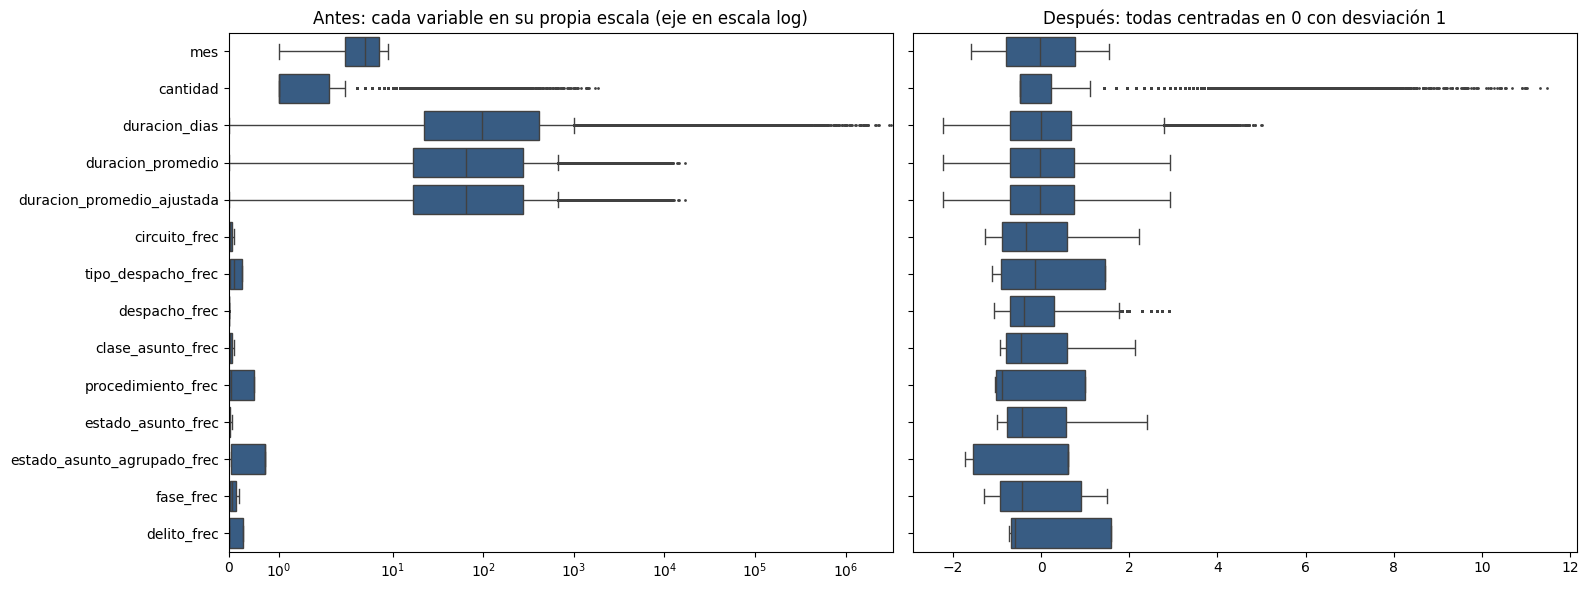

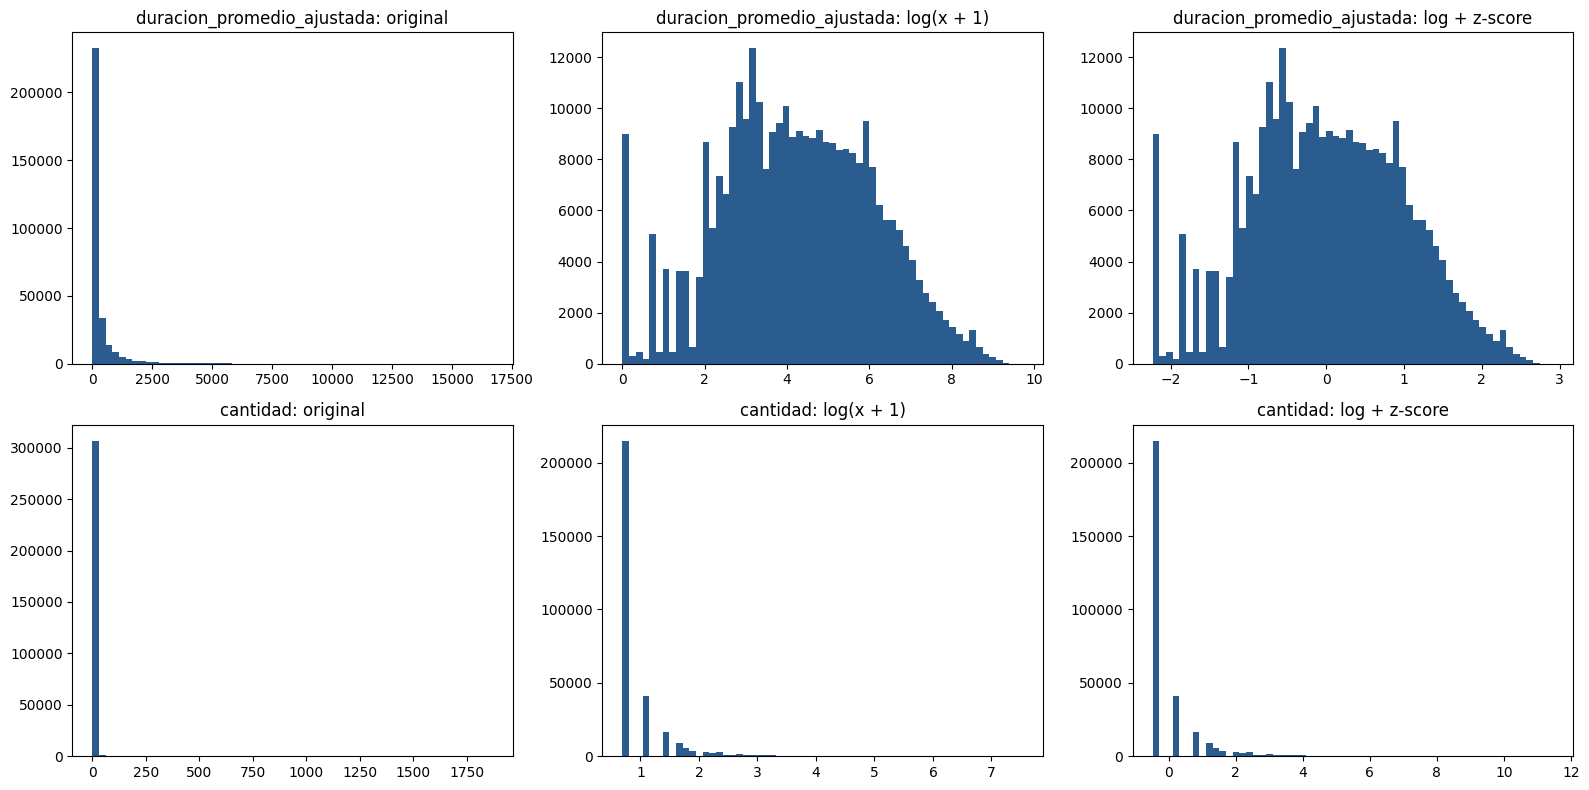

In [19]:
# Evidencia gráfica 1: escalas antes y después
fig, ejes = plt.subplots(1, 2, figsize=(16, 6))
sns.boxplot(data=df_transformado[COLUMNAS_ESCALAR], orient="h", ax=ejes[0], color="#2b5c8f", fliersize=1)
ejes[0].set_xscale("symlog")
ejes[0].set_xlim(left=0)
ejes[0].set_title("Antes: cada variable en su propia escala (eje en escala log)")
sns.boxplot(data=df_escalado[COLUMNAS_ESCALAR], orient="h", ax=ejes[1], color="#2b5c8f", fliersize=1)
ejes[1].set_title("Después: todas centradas en 0 con desviación 1")
ejes[1].set_yticklabels([])
plt.tight_layout()
plt.show()

# Evidencia gráfica 2: efecto del logaritmo y la estandarización en dos medidas
fig, ejes = plt.subplots(2, 3, figsize=(16, 8))
for fila, col in enumerate(["duracion_promedio_ajustada", "cantidad"]):
    original = df_transformado[col]
    pasos = [(original, "original"),
             (np.log1p(original), "log(x + 1)"),
             (df_escalado[col], "log + z-score")]
    for ax, (valores, titulo) in zip(ejes[fila], pasos):
        ax.hist(valores, bins=60, color="#2b5c8f")
        ax.set_title(f"{col}: {titulo}")
plt.tight_layout()
plt.show()

**Decisiones de la estandarización**

1. **Qué se estandarizó.** Las columnas numéricas con más de dos valores: `mes`, `cantidad`, las tres duraciones y las nueve frecuencias. Las columnas 0/1 no se tocaron porque ya están en la misma escala y así se pueden leer como "sí / no".
2. **Logaritmo primero.** `cantidad` y las duraciones tienen una cola muy larga (sección 2.2). Los histogramas muestran que, sin el logaritmo, casi todos los datos quedan en una sola barra. Con log(x + 1), `duracion_promedio_ajustada` se acerca a una campana. `cantidad` sigue concentrada a la izquierda porque el 69 % de las filas tiene un solo expediente, pero su rango baja de 1 871 a menos de 8 y los grupos grandes ya no dominan la media.
3. **Z-score en vez de min-max.** Con min-max, el 75 % de las filas de `duracion_dias` quedaría por debajo de 0.00013 por culpa del valor máximo. El z-score, después del logaritmo, no depende de un solo valor extremo. La tabla confirma que todas las columnas quedaron con media 0 y desviación 1.
4. **Para la sección 4.**
   - En `df_escalado`, las duraciones y `cantidad` están en escala logarítmica estandarizada. Para hablar en días se usa `df_transformado`, o se revierte con `escalador.inverse_transform` y `np.expm1`.
   - Para la correlación conviene usar `df_escalado`, porque el logaritmo reduce el efecto de los valores extremos.
5. **Limitación.** Igual que en la sección 2, la media, la desviación y las frecuencias se calcularon con todo el conjunto. En un modelo real se calculan solo con los datos de entrenamiento y después se aplican a los de prueba.

---
## 4. Análisis y resultados (Josué)

Pendiente:
- [ ] Correlaciones y gráficos
- [ ] Variable dependiente
- [ ] Modelo propuesto (clasificación o regresión) y justificación
- [ ] Guardar el dataset final como `data_process.csv`